In [1]:
import socket
import time
import os

# === CONFIGURATION ===
SAVE_DIR = r"C:\Users\USERNAME\Desktop\S11_results\CHIP1_1" 
MEASUREMENT_COUNT = 20   #number of Measurments


# Ensure save directory exists
os.makedirs(SAVE_DIR, exist_ok=True)

# === SCPI Functions ===
def send_cmd(sock, scpi):
    sock.send((scpi + '\n').encode())

def send_query(sock, scpi):
    sock.send((scpi + '\n').encode())
    response = b""
    while not response.endswith(b'\n'):
        response += sock.recv(1024)
    return response.decode().strip()

# === Connect to eVNA SCPI API ===
# sock.close()
sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
sock.settimeout(50)
sock.connect(('localhost', 5026))
print("✅ Connected to eVNA SCPI API")

# === Discover and connect to device ===
evna_list = send_query(sock, 'SYSTEM:DISCOVER?')
device = evna_list.split(',')[0]
send_cmd(sock, f'SYSTEM:CONNECT {device}')
#send_cmd(sock, 'SYSTEM:PRESET')
time.sleep(1)

# === Set up measurement ===
send_cmd(sock, 'INIT:CONT 1')
send_cmd(sock, 'TRIG:SEQ:SOUR BUS')
send_cmd(sock, 'CALC:PAR:DEF S11')

send_cmd(sock, 'MMEM:STOR:SNP:FORM DB')
send_cmd(sock, 'MMEM:STOR:SNP:NPORT 1')
send_cmd(sock, 'MMEM:STOR:SNP:TYPE:S1P 1')

# === Loop to collect and save 20 traces ===
for i in range(MEASUREMENT_COUNT):
    print(f"📡 Measuring {i+1}/{MEASUREMENT_COUNT}")
    send_cmd(sock, 'TRIG:SEQ:SING')
    send_query(sock, '*OPC?')  # Wait for completion

    filename = os.path.join(SAVE_DIR, f"evna_trace_{i:04d}.s1p").replace("\\", "\\\\")
    send_cmd(sock, f'MMEM:STOR:SNP:DATA "{filename}"')

print("✅ Measurements saved!")
sock.close()


✅ Connected to eVNA SCPI API
📡 Measuring 1/20
📡 Measuring 2/20
📡 Measuring 3/20
📡 Measuring 4/20
📡 Measuring 5/20
📡 Measuring 6/20
📡 Measuring 7/20
📡 Measuring 8/20
📡 Measuring 9/20
📡 Measuring 10/20
📡 Measuring 11/20
📡 Measuring 12/20
📡 Measuring 13/20
📡 Measuring 14/20
📡 Measuring 15/20
📡 Measuring 16/20
📡 Measuring 17/20
📡 Measuring 18/20
📡 Measuring 19/20
📡 Measuring 20/20
✅ Measurements saved!


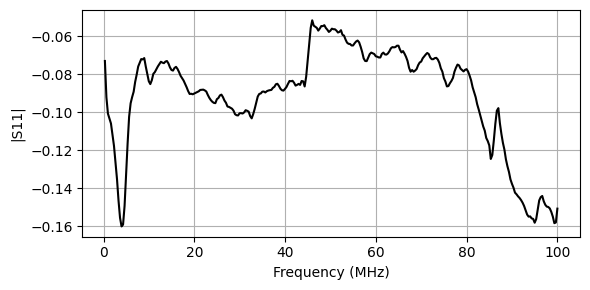

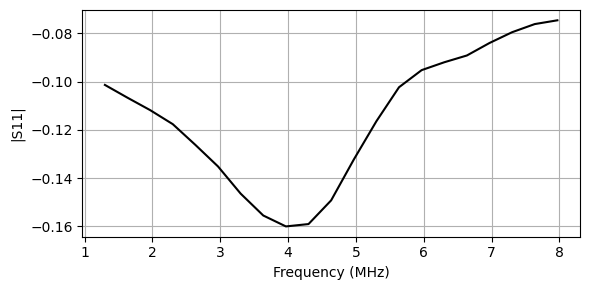

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from scipy.signal import savgol_filter

folder_path= SAVE_DIR
# --- Step 1: Collect all data ---
freq_dict = defaultdict(list)

for file_name in os.listdir(folder_path):
    if file_name.endswith(".s1p"):
        file_path = os.path.join(folder_path, file_name)
        with open(file_path, "r") as f:
            for line in f:
                if line.startswith("!") or line.startswith("#") or not line.strip():
                    continue
                parts = line.split()
                if len(parts) >= 2:
                    freq = float(parts[0])
                    mag = float(parts[1])
                    freq_dict[freq].append(mag)

# --- Step 2: Average values per frequency ---
freqs = sorted(freq_dict.keys())
avg_mags = [np.mean(freq_dict[f]) for f in freqs]

# --- Step 3: Plot for ALL frequencies ---
plt.figure(figsize=(6,3))
plt.plot(np.array(freqs)/1e6, savgol_filter(avg_mags, 7, 3), linewidth=1.5, color='black')
plt.xlabel("Frequency (MHz)")
plt.ylabel("|S11|")
# plt.title("Average S11 Magnitude vs Frequency (All Range)")
plt.grid(True)
plt.tight_layout()
plt.show()
# plt.savefig(os.path.join(folder_path, "S11_avg_all_range.pdf"))
plt.close()

# --- Step 4: Plot for 1 MHz – 8 MHz ---
f_min = 1e6
f_max = 8e6

freqs_filtered = [f for f in freqs if f_min <= f <= f_max]
avg_mags_filtered = [np.mean(freq_dict[f]) for f in freqs_filtered]

plt.figure(figsize=(6,3))
plt.plot(np.array(freqs_filtered)/1e6, savgol_filter(avg_mags_filtered, 7, 3), linewidth=1.5, color='black')
plt.xlabel("Frequency (MHz)")
plt.ylabel("|S11|")
# plt.title("Average S11 Magnitude vs Frequency (1–8 MHz)")
plt.grid(True)
plt.tight_layout()
plt.show()
# plt.savefig(os.path.join(folder_path, "S11_avg_1to8MHz.pdf"))
plt.close()

# print("✅ Saved: S11_avg_all_range.pdf and S11_avg_1to8MHz.pdf")
